Use SHAP values to interpret model predictions by manually computing Shapley values, visualizing their impact on individual predictions without using built-in SHAP libraries, and analyzing feature contribution variability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import math

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset shape:", df.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", features)

Dataset shape: (79, 19)
Training samples: 63
Testing samples: 16
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [2]:
model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model accuracy:", round(accuracy_score(y_test, y_pred), 4))

Model accuracy: 0.75


In [3]:
background = X_train.sample(
    n=min(30, len(X_train)),
    random_state=42
).reset_index(drop=True)

def predict_probability(data):
    data = pd.DataFrame(data, columns=features)
    return model.predict_proba(data)[:, 1]

def manual_shapley_values(instance, background):
    n_features = len(features)
    shap_values = np.zeros(n_features)

    instance = np.asarray(instance, dtype=float)

    for i in range(n_features):
        other_features = [j for j in range(n_features) if j != i]

        for size in range(n_features):
            for subset in itertools.combinations(other_features, size):
                subset = set(subset)

                weight = (
                    math.factorial(len(subset))
                    * math.factorial(n_features - len(subset) - 1)
                    / math.factorial(n_features)
                )

                with_feature = background.copy()
                without_feature = background.copy()

                for j in subset:
                    with_feature.iloc[:, j] = instance[j]
                    without_feature.iloc[:, j] = instance[j]

                with_feature.iloc[:, i] = instance[i]

                value_with = predict_probability(with_feature).mean()
                value_without = predict_probability(without_feature).mean()

                shap_values[i] += weight * (value_with - value_without)

    return shap_values

print("Manual Shapley function is ready.")

Manual Shapley function is ready.


In [4]:
sample_index = 0

patient = X_test.iloc[sample_index]
actual_value = y_test.iloc[sample_index]
predicted_value = model.predict(patient.to_frame().T)[0]
predicted_probability = model.predict_proba(
    patient.to_frame().T
)[0, 1]

shap_values = manual_shapley_values(patient, background)

base_value = predict_probability(background).mean()

explanation_df = pd.DataFrame({
    "Feature": features,
    "Feature Value": patient.values,
    "Shapley Value": shap_values
})

explanation_df["Impact"] = np.where(
    explanation_df["Shapley Value"] > 0,
    "Increases prediction",
    "Decreases prediction"
)

explanation_df = explanation_df.sort_values(
    "Shapley Value",
    key=abs,
    ascending=False
)

print("Actual class:", actual_value)
print("Predicted class:", predicted_value)
print("Predicted probability for class 1:", round(predicted_probability, 4))
print("Baseline probability:", round(base_value, 4))
print("\nFeature contributions:")
print(explanation_df.to_string(index=False))

print("\nSum of contributions:", round(shap_values.sum(), 6))
print("Baseline + contributions:", round(base_value + shap_values.sum(), 6))

Actual class: 0
Predicted class: 0
Predicted probability for class 1: 0.33
Baseline probability: 0.7193

Feature contributions:
 Feature  Feature Value  Shapley Value               Impact
     age           31.0      -0.406000 Decreases prediction
trestbps          134.0      -0.073278 Decreases prediction
 oldpeak            4.1       0.052111 Increases prediction
    chol          255.0       0.039917 Increases prediction
 thalach          174.0      -0.002083 Decreases prediction

Sum of contributions: -0.389333
Baseline + contributions: 0.33


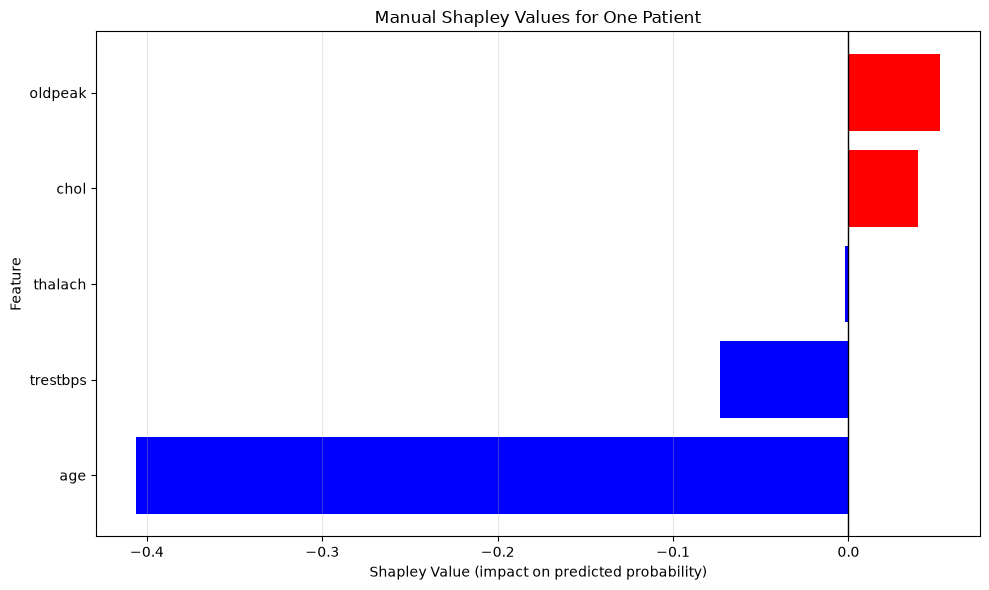

In [5]:
plt.figure(figsize=(10, 6))

plot_df = explanation_df.sort_values("Shapley Value")

bar_colors = [
    "red" if value > 0 else "blue"
    for value in plot_df["Shapley Value"]
]

plt.barh(
    plot_df["Feature"],
    plot_df["Shapley Value"],
    color=bar_colors
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Shapley Value (impact on predicted probability)")
plt.ylabel("Feature")
plt.title("Manual Shapley Values for One Patient")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
n_samples = min(20, len(X_test))

sample_data = X_test.iloc[:n_samples]

all_shap_values = []

for _, patient in sample_data.iterrows():
    values = manual_shapley_values(patient, background)
    all_shap_values.append(values)

shap_df = pd.DataFrame(
    all_shap_values,
    columns=features,
    index=sample_data.index
)

print("Shapley values calculated for", n_samples, "patients.")
print(shap_df.head())

Shapley values calculated for 16 patients.
         age  trestbps      chol   thalach   oldpeak
49 -0.406000 -0.073278  0.039917 -0.002083  0.052111
1   0.064517 -0.030178 -0.203344 -0.096539  0.046211
47 -0.179700 -0.019200 -0.187394 -0.030339 -0.102700
28  0.032389 -0.094222  0.113639  0.012889  0.055972
39 -0.040617  0.097856  0.086856  0.000383  0.066189


          Mean Absolute Impact  Mean Signed Impact  Contribution Variability
age                    0.13607            -0.00768                   0.18125
chol                   0.09737             0.00089                   0.11738
trestbps               0.06199             0.00470                   0.07474
oldpeak                0.05927            -0.00071                   0.06897
thalach                0.02016            -0.00840                   0.03323


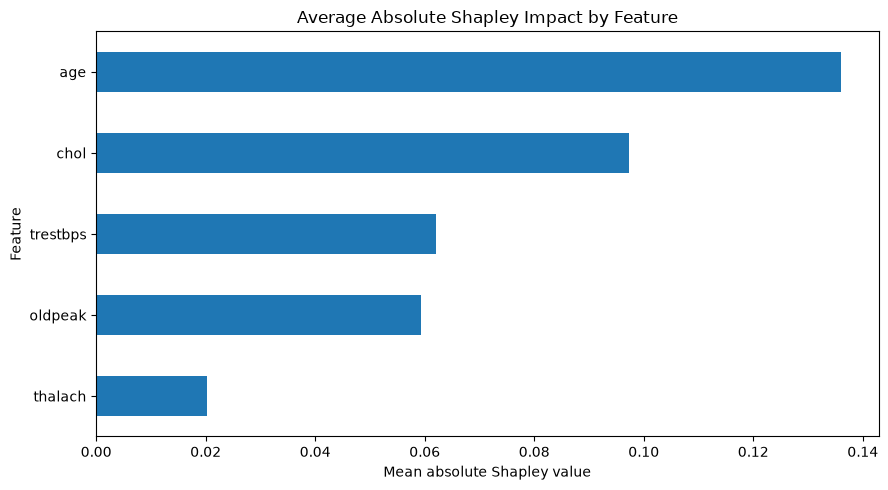

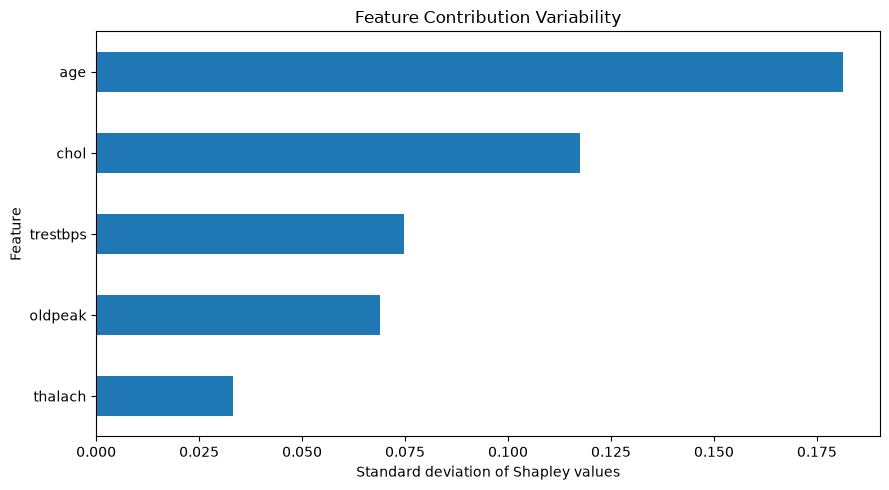

In [7]:
mean_abs_shap = shap_df.abs().mean()
mean_shap = shap_df.mean()
std_shap = shap_df.std()

variability_df = pd.DataFrame({
    "Mean Absolute Impact": mean_abs_shap,
    "Mean Signed Impact": mean_shap,
    "Contribution Variability": std_shap
}).sort_values("Mean Absolute Impact", ascending=False)

print(variability_df.round(5))

variability_df["Mean Absolute Impact"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Average Absolute Shapley Impact by Feature"
)

plt.xlabel("Mean absolute Shapley value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

variability_df["Contribution Variability"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Feature Contribution Variability"
)

plt.xlabel("Standard deviation of Shapley values")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()